# Week 8: Decision Trees (ID3)

## Student Practice Notebook

**Name:** CHINTHALACHERUVU AVINASH REDDY
**Roll Number:** AP24110010136
**Date:** 09-10-2026

## Learning Objectives

After completing this lab, you will be able to:

- Compute entropy and information gain, by hand and in code
- Build an ID3 decision tree by hand on a small table (the exam-style problem)
- Fit and read a `DecisionTreeClassifier`
- Explain how tree depth controls overfitting (same idea as K in Week 7 and degree in Week 6)
- Explain how a tree differs from KNN: it asks questions about *features*, it does not measure *distance*

### Why this week matters
KNN (Week 7) classified by "who is closest?". A decision tree classifies by asking a chain of yes/no questions about features, and you can read the questions. That readability is why trees are used in credit, healthcare and fraud work, and why every ensemble in Unit V is built from them.


## Part 0 — Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris, load_digits
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score

%matplotlib inline
np.random.seed(1)


## Part 1 — Entropy and Information Gain

**Entropy** measures how mixed a set of labels is: $H = -\sum p_i \log_2 p_i$. A pure set (all one class) has entropy 0. A 50/50 two-class set has entropy 1.

**Information gain** of splitting on an attribute = entropy before − weighted average entropy after. ID3 always picks the attribute with the highest gain.

### 1.1 Demo: entropy in code


In [2]:
def entropy(counts):
    counts = np.array(counts, dtype=float)
    p = counts[counts > 0] / counts.sum()
    return float(-np.sum(p * np.log2(p))) + 0.0

print('Pure set      [10, 0]:', entropy([10, 0]))
print('50/50 set     [5, 5] :', entropy([5, 5]))
print('Skewed set    [9, 1] :', entropy([9, 1]))


Pure set      [10, 0]: 0.0
50/50 set     [5, 5] : 1.0
Skewed set    [9, 1] : 0.4689955935892812


**Your answer:** A 70/30 split has higher entropy than a 90/10 split because its classes are more mixed and harder to predict.

### Student Practice — entropy of a split

A parent node has 8 Yes and 6 No. A candidate split sends 6 samples to the left child (6 Yes, 0 No) and 8 samples to the right child (2 Yes, 6 No). Compute the entropy of the parent and the information gain of the split.


In [3]:
# Parent: 8 Yes, 6 No. Left: 6 Yes, 0 No. Right: 2 Yes, 6 No.
parent_entropy = entropy([8, 6])
left_entropy = entropy([6, 0])
right_entropy = entropy([2, 6])
weighted_child_entropy = (6/14)*left_entropy + (8/14)*right_entropy
information_gain = parent_entropy - weighted_child_entropy
print("Parent entropy:", round(parent_entropy, 4))
print("Information gain:", round(information_gain, 4))

Parent entropy: 0.9852
Information gain: 0.5216


## Part 2 — ID3 by Hand (the exam-style problem)

Classic 14-day "play tennis" table. Target: `Play`.


In [4]:
tennis = pd.DataFrame({
    'Outlook':     ['Sunny','Sunny','Overcast','Rain','Rain','Rain','Overcast','Sunny','Sunny','Rain','Sunny','Overcast','Overcast','Rain'],
    'Temperature': ['Hot','Hot','Hot','Mild','Cool','Cool','Cool','Mild','Cool','Mild','Mild','Mild','Hot','Mild'],
    'Humidity':    ['High','High','High','High','Normal','Normal','Normal','High','Normal','Normal','Normal','High','Normal','High'],
    'Wind':        ['Weak','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Weak','Weak','Strong','Strong','Weak','Strong'],
    'Play':        ['No','No','Yes','Yes','Yes','No','Yes','No','Yes','Yes','Yes','Yes','Yes','No'],
})
tennis


,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


In [5]:
def info_gain(df, attribute, target='Play'):
    total = entropy(df[target].value_counts())
    weighted = 0
    for value, subset in df.groupby(attribute):
        weighted += len(subset) / len(df) * entropy(subset[target].value_counts())
    return total - weighted

print('Root entropy:', round(entropy(tennis['Play'].value_counts()), 4))
print('Gain(Wind)  :', round(info_gain(tennis, 'Wind'), 4))


Root entropy: 0.9403
Gain(Wind)  : 0.0481


### Student Practice — find the root

1. Compute the information gain for `Outlook`, `Temperature` and `Humidity` using `info_gain`.
2. Which attribute does ID3 pick as the root?
3. For the root's branch that is **not** pure, which attribute would you split on next? (Filter `tennis` to that branch and recompute gains.)


In [6]:
# Information gain for each candidate attribute
for attr in ['Outlook', 'Temperature', 'Humidity']:
    print(attr, round(info_gain(tennis, attr), 4))

# ID3 chooses Outlook (highest information gain).
# The Sunny branch is not pure; compare candidate gains within it.
sunny = tennis[tennis['Outlook'] == 'Sunny']
print("\\nSunny branch gains:")
for attr in ['Temperature', 'Humidity', 'Wind']:
    print(attr, round(info_gain(sunny, attr), 4))

Outlook 0.2467
Temperature 0.0292
Humidity 0.1518
\nSunny branch gains:
Temperature 0.571
Humidity 0.971
Wind 0.02


**Your answer:** A pure branch contains only one class, so its label is already certain and no further split is needed.

## Part 3 — `DecisionTreeClassifier` on Iris

Same Iris split as Week 7, so you can compare directly. Note: **trees do not need feature scaling**, because they compare a feature to a threshold, not distances between points. That is a real difference from KNN.


Test accuracy: 0.9555555555555556


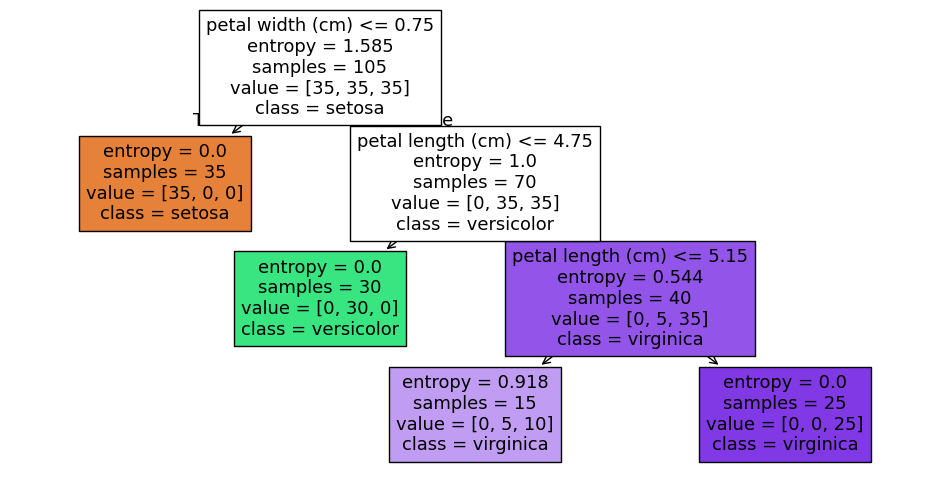

In [7]:
iris = load_iris(as_frame=True)
X, y = iris.data, iris.target
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

tree = DecisionTreeClassifier(criterion='entropy', max_depth=3, random_state=1)
tree.fit(X_train, y_train)
print('Test accuracy:', accuracy_score(y_test, tree.predict(X_test)))

plt.figure(figsize=(12, 6))
plot_tree(tree, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()


### Student Practice — depth sweep

Sweep `max_depth` from 1 to 15. Record train and test accuracy for each, plot both, and report the depth with the best test accuracy.


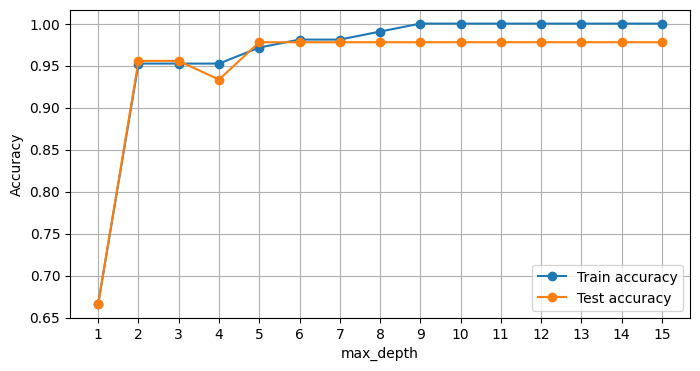

Best test depth: 5
Best test accuracy: 0.9778


In [8]:
depths = range(1, 16)
train_scores, test_scores = [], []
for depth in depths:
    model = DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=1)
    model.fit(X_train, y_train)
    train_scores.append(accuracy_score(y_train, model.predict(X_train)))
    test_scores.append(accuracy_score(y_test, model.predict(X_test)))

plt.figure(figsize=(8, 4))
plt.plot(list(depths), train_scores, marker='o', label='Train accuracy')
plt.plot(list(depths), test_scores, marker='o', label='Test accuracy')
plt.xlabel('max_depth')
plt.ylabel('Accuracy')
plt.xticks(list(depths))
plt.legend()
plt.grid(True)
plt.show()
best_depth = list(depths)[int(np.argmax(test_scores))]
print("Best test depth:", best_depth)
print("Best test accuracy:", round(max(test_scores), 4))

**Your answer:** `max_depth` plays the role of polynomial degree in Week 6 and K in Week 7. Too small underfits; too large can overfit.

# Mini Project A: Digits, Again (Image Track — continuing from Week 7)

Last week KNN reached about 98% on the digits dataset. Now fit a decision tree on the **same split** and ask two new questions: how does it compare, and **which pixels does the tree actually use?**


In [9]:
digits = load_digits()
Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    digits.data, digits.target, test_size=0.3, random_state=1, stratify=digits.target)

# KNN baseline from Week 7 (scaled, K=3)
sc = StandardScaler().fit(Xd_train)
knn = KNeighborsClassifier(n_neighbors=3).fit(sc.transform(Xd_train), yd_train)
print('KNN  test accuracy:', accuracy_score(yd_test, knn.predict(sc.transform(Xd_test))))


KNN  test accuracy: 0.9796296296296296


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on the **unscaled** `Xd_train`. Print test accuracy. (Why is no scaling needed?)
2. Try `max_depth` values 3, 6, 10 and report test accuracy for each.
3. Take `tree.feature_importances_` (64 values), reshape to 8×8 and show it with `plt.imshow`. Which region of the image does the tree rely on?


Tree test accuracy: 0.8815
KNN test accuracy: 0.9796
max_depth=3: test accuracy=0.5296
max_depth=6: test accuracy=0.8537
max_depth=10: test accuracy=0.8796


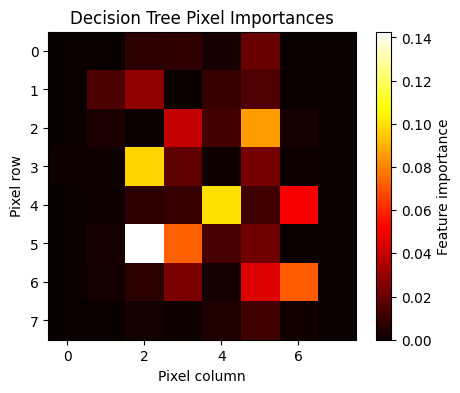

In [10]:
# 1. Fit a decision tree on unscaled pixel features.
tree = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree.fit(Xd_train, yd_train)
print("Tree test accuracy:", round(accuracy_score(yd_test, tree.predict(Xd_test)), 4))
print("KNN test accuracy:", round(accuracy_score(yd_test, knn.predict(sc.transform(Xd_test))), 4))

# 2. Compare selected maximum depths.
for depth in [3, 6, 10]:
    model = DecisionTreeClassifier(criterion='entropy', max_depth=depth, random_state=1)
    model.fit(Xd_train, yd_train)
    print(f"max_depth={depth}: test accuracy={accuracy_score(yd_test, model.predict(Xd_test)):.4f}")

# 3. Visualize pixel importance as an 8x8 image.
importances = tree.feature_importances_.reshape(8, 8)
plt.figure(figsize=(5, 4))
plt.imshow(importances, cmap='hot')
plt.colorbar(label='Feature importance')
plt.title('Decision Tree Pixel Importances')
plt.xlabel('Pixel column')
plt.ylabel('Pixel row')
plt.show()

**Your answer:** The tree is generally less accurate than KNN on digits because a single tree makes axis-aligned pixel splits and may overfit. Important pixels show which image regions help its decisions.

# Mini Project B: Reading a Tree on Text (NLP Track — continuing from Week 7)

Same six labeled sentences and same bag-of-words vectors as Week 7. A tree gives you something KNN cannot: **the words it chose to split on.**


In [11]:
sentences = [
    'the cricket team won the match',
    'the batsman scored a century today',
    'chop the onions and boil the pasta',
    'add salt and simmer the curry',
    'the new phone has a faster processor',
    'the laptop battery lasts all day',
]
labels = ['sports', 'sports', 'cooking', 'cooking', 'tech', 'tech']

vocab = sorted(set(w for s in sentences for w in s.lower().split()))

def to_vector(sentence, vocab):
    words = sentence.lower().split()
    return np.array([words.count(w) for w in vocab])

X_text = np.array([to_vector(s, vocab) for s in sentences])


### Student Practice

1. Fit a `DecisionTreeClassifier(criterion='entropy', random_state=1)` on `X_text`, `labels`.
2. Print the tree with `export_text(tree, feature_names=vocab)`. Which words does it split on?
3. Predict the topic of `'the striker scored a goal'` and of your own ambiguous sentence from Week 7.


In [12]:
tree_text = DecisionTreeClassifier(criterion='entropy', random_state=1)
tree_text.fit(X_text, labels)
print(export_text(tree_text, feature_names=vocab))

test_sentences = ['the striker scored a goal', 'the phone battery lasts all day']
for sentence in test_sentences:
    vector = to_vector(sentence, vocab).reshape(1, -1)
    print(repr(sentence), "->", tree_text.predict(vector)[0])

# Own ambiguous sentence example
own_sentence = 'the team discussed the new game'
print(repr(own_sentence), "->", tree_text.predict(to_vector(own_sentence, vocab).reshape(1, -1))[0])

|--- and <= 0.50
|   |--- has <= 0.50
|   |   |--- laptop <= 0.50
|   |   |   |--- class: sports
|   |   |--- laptop >  0.50
|   |   |   |--- class: tech
|   |--- has >  0.50
|   |   |--- class: tech
|--- and >  0.50
|   |--- class: cooking

'the striker scored a goal' -> sports
'the phone battery lasts all day' -> sports
'the team discussed the new game' -> sports


**Your answer:** The split words may change because the tree learns from the examples it sees. With very little data, its rules can be unstable and may not generalize well.

## Summary

| What we did | Why it matters |
|---|---|
| Entropy and information gain | The rule ID3 uses to choose every split |
| ID3 by hand on the tennis table | Exam-style problem, show your working |
| `DecisionTreeClassifier` and depth sweep | Third version of the bias-variance knob (degree, K, depth) |
| Mini A: digits | Tree vs KNN on the same data, plus which pixels matter |
| Mini B: text | A tree you can read, and why tiny data makes it fragile |

**Next week:** Naive Bayes, a probabilistic classifier. Same digits and sentences again.
